<a href="https://colab.research.google.com/github/MakhloufiMahdi/customer-churn-intelligence-platform/blob/main/notebooks/03_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Télécharger le dataset original
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Nettoyer TotalCharges
df["TotalCharges"] = (
    df["TotalCharges"]
    .astype(str)
    .str.strip()
    .replace("", np.nan)
)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Remplacer les 11 valeurs vides des clients tenure = 0
condition = (
    df["TotalCharges"].isna()
    & (df["tenure"] == 0)
)

df.loc[condition, "TotalCharges"] = 0

# Vérification
print("Dataset chargé :", df.shape)
print("Valeurs manquantes :", df.isna().sum().sum())
print("TotalCharges type :", df["TotalCharges"].dtype)

display(df.head())

Dataset chargé : (7043, 21)
Valeurs manquantes : 0
TotalCharges type : float64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
churn_counts = df["Churn"].value_counts()

display(churn_counts)

print("\nPourcentages :")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

,count
Churn,
No,5174
Yes,1869



Pourcentages :


,proportion
Churn,
No,73.46
Yes,26.54


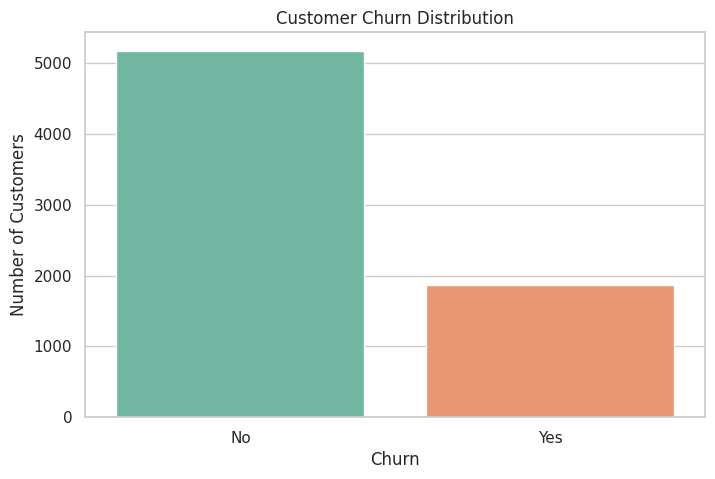

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [8]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn = contract_churn.round(2)

display(contract_churn)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


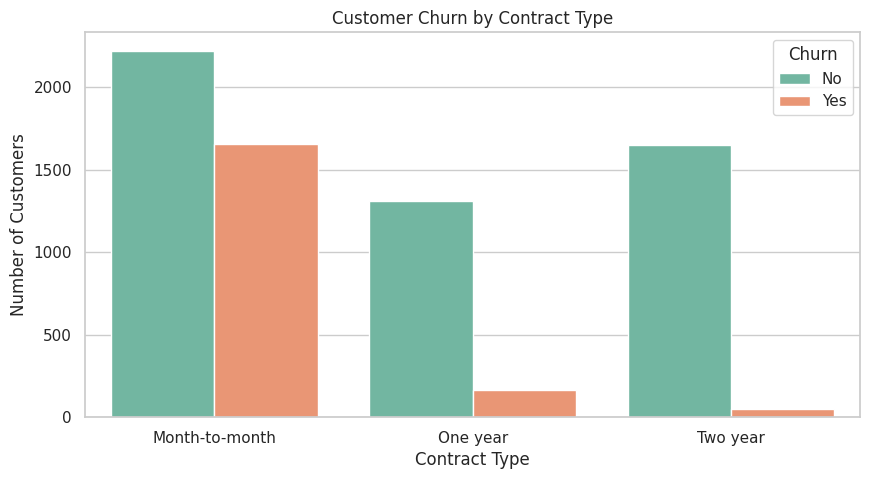

In [9]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

### EDA Finding 1 — Customer Churn by Contract Type

**Observation:**

Customer churn varies significantly across contract types:

- Month-to-month: 42.71%
- One year: 11.27%
- Two year: 2.83%

**Business interpretation:**

Customers with month-to-month contracts are substantially more likely to churn than customers with long-term contracts.

**Business recommendation:**

Prioritize retention strategies for month-to-month customers, particularly those showing additional signs of churn risk.

**Conclusion:**

Contract type appears to be an important feature for customer churn prediction. This relationship is observational and does not establish causation.

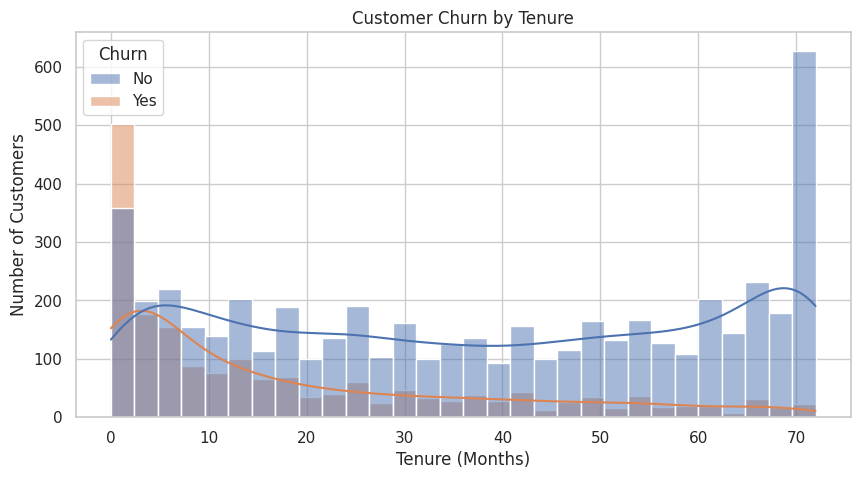

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="layer"
)

plt.title("Customer Churn by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [11]:
tenure_churn = df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(tenure_churn)

,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72



## EDA Finding 2 — Customer Churn by Tenure

### Observation

- Average tenure of retained customers: 37.57 months.
- Average tenure of churned customers: 17.98 months.
- Median tenure of retained customers: 38 months.
- Median tenure of churned customers: 10 months.

### Business Interpretation

Customers who churn tend to have shorter relationships with the telecom company.

The first months of the customer relationship may represent a particularly sensitive period.

### Business Recommendation

Develop early customer retention strategies and monitor recently acquired customers for signs of churn risk.

### Conclusion

Tenure appears to be an important feature for customer churn prediction.


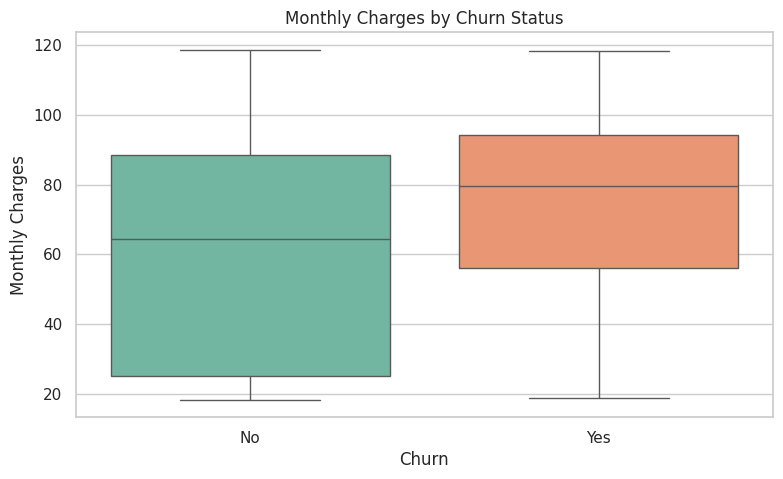

In [12]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [13]:
monthly_charges_analysis = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(monthly_charges_analysis)

,count,mean,median,min,max
Churn,,,,,
No,5174,61.27,64.43,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35



## EDA Finding 3 — Customer Churn by Monthly Charges

### Observation

- Average monthly charges of retained customers: 61.27.
- Average monthly charges of churned customers: 74.44.
- Median monthly charges of retained customers: 64.43.
- Median monthly charges of churned customers: 79.65.

### Business Interpretation

Customers who churn tend to have higher monthly charges than customers who remain with the company.

The difference may be related to service combinations, pricing, or customer contract characteristics.

### Business Recommendation

Investigate customers with high monthly charges and identify opportunities to improve perceived value, pricing satisfaction, and retention.

### Conclusion

MonthlyCharges appears to be a potentially useful feature for customer churn prediction. Further analysis is needed to understand the relationship.


In [14]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

display(payment_churn.round(2))

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


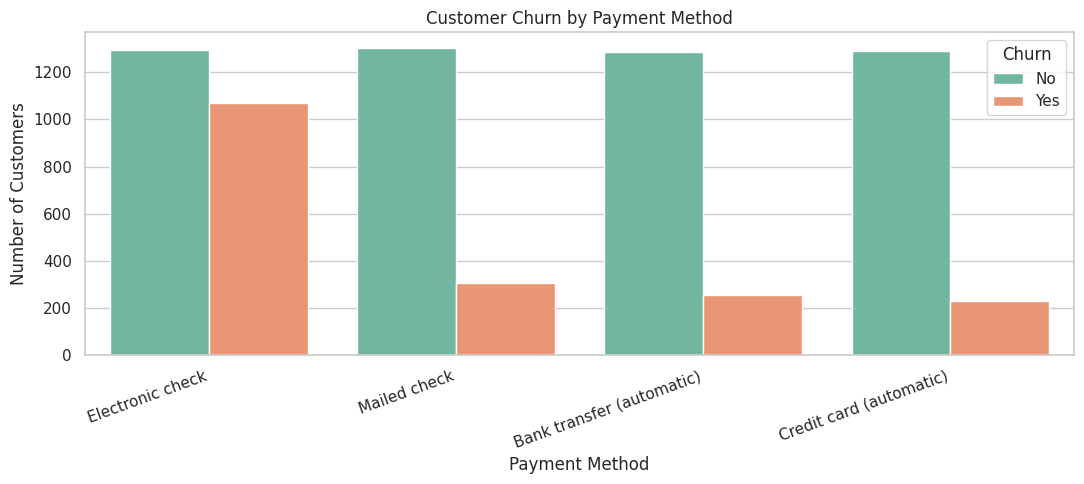

In [15]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()


## EDA Finding 4 — Customer Churn by Payment Method

### Observation

- Electronic check: 45.29% churn.
- Mailed check: 19.11% churn.
- Bank transfer (automatic): 16.71% churn.
- Credit card (automatic): 15.24% churn.

### Business Interpretation

Customers using electronic checks have a substantially higher churn rate than customers using automatic payment methods.

### Business Recommendation

Investigate the customer experience of electronic check users and evaluate incentives for switching to automatic payment methods.

### Conclusion

PaymentMethod appears to be an important feature for customer churn analysis. The observed relationship does not establish causation.


In [16]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

display(internet_churn.round(2))

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


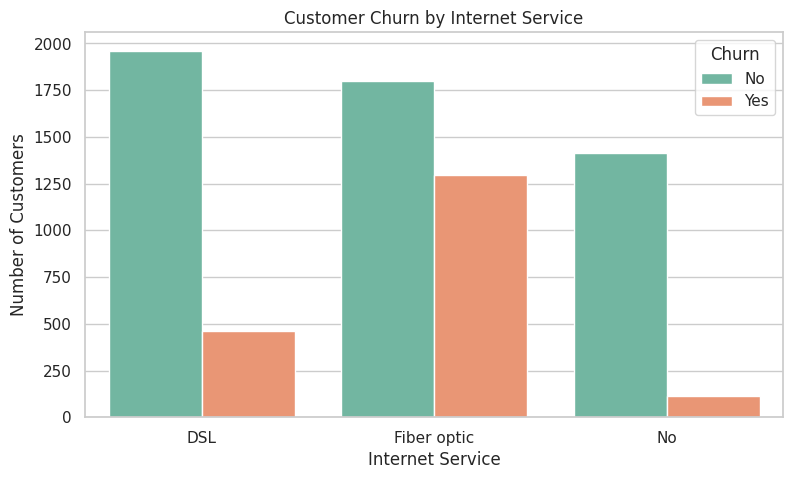

In [17]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()


## EDA Finding 5 — Customer Churn by Internet Service

### Observation

- Fiber optic: 41.89% churn.
- DSL: 18.96% churn.
- No Internet service: 7.40% churn.

### Business Interpretation

Customers using Fiber optic services have a substantially higher churn rate than customers using DSL or no Internet service.

### Business Recommendation

Investigate Fiber optic customer satisfaction, service quality, pricing, and technical support experience.

### Conclusion

InternetService appears to be an important feature for customer churn analysis. The observed relationship does not establish causation.


In [18]:
services = ["OnlineSecurity", "TechSupport"]

for service in services:

    print(f"\nChurn by {service}")

    result = pd.crosstab(
        df[service],
        df["Churn"],
        normalize="index"
    ) * 100

    display(result.round(2))


Churn by OnlineSecurity


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61



Churn by TechSupport


Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


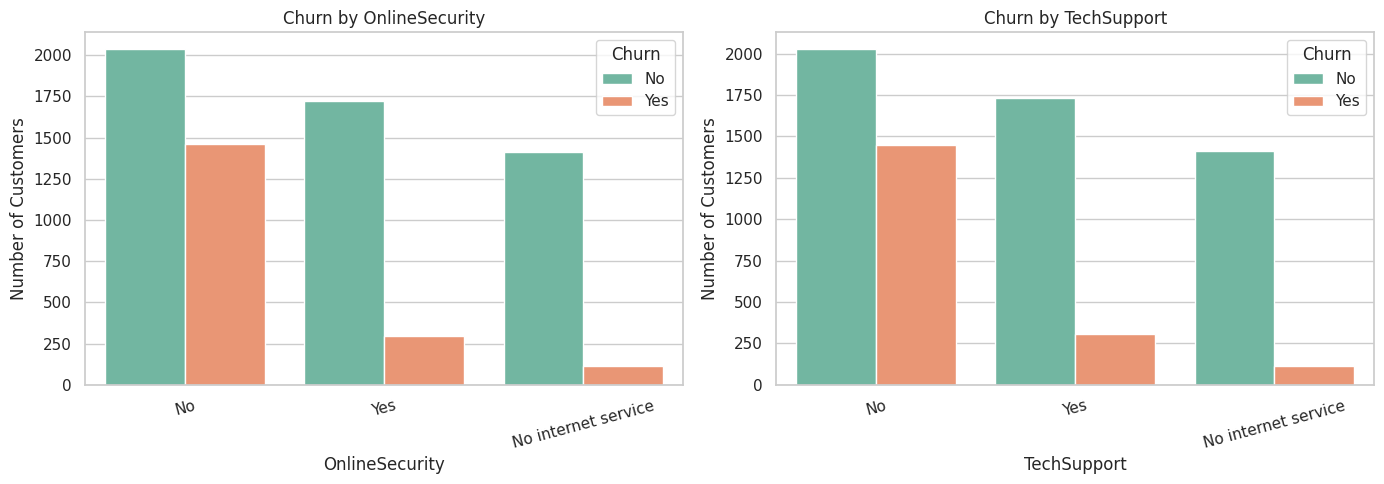

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, service in zip(axes, services):

    sns.countplot(
        data=df,
        x=service,
        hue="Churn",
        palette="Set2",
        ax=ax
    )

    ax.set_title(f"Churn by {service}")
    ax.set_xlabel(service)
    ax.set_ylabel("Number of Customers")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### EDA Finding 6 – OnlineSecurity and TechSupport

The analysis reveals a strong association between the absence of additional customer services and higher churn rates.

**OnlineSecurity:**
- Customers without OnlineSecurity have a churn rate of 41.77%.
- Customers with OnlineSecurity have a churn rate of 14.61%.

**TechSupport:**
- Customers without TechSupport have a churn rate of 41.64%.
- Customers with TechSupport have a churn rate of 15.17%.

**Key insights:**
- Customers without OnlineSecurity or TechSupport are significantly more likely to churn.
- These services may contribute to customer retention.
- Customers without these services could be potential targets for retention campaigns.

**Business recommendation:**

The company should investigate whether offering security and technical support services, or improving their accessibility, could help reduce customer churn.

**Note:** These findings show statistical associations, not causal relationships. Further analysis is needed to understand the influence of contract type, internet service, and monthly charges.

In [20]:
services = ["OnlineBackup", "DeviceProtection"]

for service in services:
    print(f"\nChurn by {service}")

    result = pd.crosstab(
        df[service],
        df["Churn"],
        normalize="index"
    ) * 100

    display(result.round(2))


Churn by OnlineBackup


Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53



Churn by DeviceProtection


Churn,No,Yes
DeviceProtection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


### EDA Finding 7 – OnlineBackup and DeviceProtection

The analysis shows an association between the absence of additional protection services and higher customer churn.

**OnlineBackup:**
- Customers without OnlineBackup have a churn rate of 39.93%.
- Customers with OnlineBackup have a churn rate of 21.53%.

**DeviceProtection:**
- Customers without DeviceProtection have a churn rate of 39.13%.
- Customers with DeviceProtection have a churn rate of 22.50%.

**Key insights:**
- Customers without these services are more likely to churn.
- OnlineBackup and DeviceProtection may be associated with improved customer retention.
- These services could be considered in customer retention strategies.

**Business recommendation:**

The company should investigate whether targeted offers for backup and device protection services could improve customer retention.

**Note:** These results indicate associations, not causal relationships. Other factors, such as contract type, tenure, and monthly charges, may also influence churn.

In [21]:
services = ["StreamingTV", "StreamingMovies"]

for service in services:
    print(f"\nChurn by {service}")

    result = pd.crosstab(
        df[service],
        df["Churn"],
        normalize="index"
    ) * 100

    display(result.round(2))


Churn by StreamingTV


Churn,No,Yes
StreamingTV,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07



Churn by StreamingMovies


Churn,No,Yes
StreamingMovies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


### EDA Finding 8 – StreamingTV and StreamingMovies

The analysis reveals relatively small differences in churn rates between customers who subscribe to streaming services and those who do not.

**StreamingTV:**
- Customers without StreamingTV have a churn rate of 33.52%.
- Customers with StreamingTV have a churn rate of 30.07%.

**StreamingMovies:**
- Customers without StreamingMovies have a churn rate of 33.68%.
- Customers with StreamingMovies have a churn rate of 29.94%.

**Key insights:**
- StreamingTV and StreamingMovies show weaker associations with churn compared with OnlineSecurity, TechSupport, OnlineBackup, and DeviceProtection.
- Having a streaming subscription is associated with a slightly lower churn rate, but the difference is relatively small.

**Business recommendation:**

Streaming services should not be considered the primary focus of retention campaigns based on these results alone. Other customer characteristics and service factors should also be investigated.

**Note:** These findings represent associations, not causal relationships.

In [22]:
customer_features = [
    "Partner",
    "Dependents",
    "SeniorCitizen"
]

for feature in customer_features:
    print(f"\nChurn by {feature}")

    result = pd.crosstab(
        df[feature],
        df["Churn"],
        normalize="index"
    ) * 100

    display(result.round(2))


Churn by Partner


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66



Churn by Dependents


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45



Churn by SeniorCitizen


Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


### EDA Finding 9 – Customer Demographics

The analysis reveals meaningful differences in churn rates across customer demographic characteristics.

**Partner:**
- Customers without a partner have a churn rate of 32.96%.
- Customers with a partner have a churn rate of 19.66%.

**Dependents:**
- Customers without dependents have a churn rate of 31.28%.
- Customers with dependents have a churn rate of 15.45%.

**SeniorCitizen:**
- Non-senior customers have a churn rate of 23.61%.
- Senior customers have a churn rate of 41.68%.

**Key insights:**
- Customers without partners or dependents show higher churn rates.
- Senior customers have a substantially higher churn rate than non-senior customers.
- These demographic variables may help identify customer segments that require targeted retention strategies.

**Business recommendation:**

The company should investigate the needs of senior customers and customers without dependents or partners to develop more suitable customer support and retention strategies.

**Note:** These results show associations, not causal relationships. Demographic characteristics should be interpreted alongside contract type, tenure, service subscriptions, and monthly charges.

In [23]:
features = ["PaperlessBilling", "MultipleLines"]

for feature in features:
    print(f"\nChurn by {feature}")

    result = pd.crosstab(
        df[feature],
        df["Churn"],
        normalize="index"
    ) * 100

    display(result.round(2))


Churn by PaperlessBilling


Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57



Churn by MultipleLines


Churn,No,Yes
MultipleLines,,
No,74.96,25.04
No phone service,75.07,24.93
Yes,71.39,28.61


### EDA Finding 10 – PaperlessBilling and MultipleLines

The analysis reveals different levels of association between these two features and customer churn.

**PaperlessBilling:**
- Customers using paperless billing have a churn rate of 33.57%.
- Customers using paper billing have a churn rate of 16.33%.
- The churn rate is approximately 2.06 times higher among customers using paperless billing.

**MultipleLines:**
- Customers without multiple lines have a churn rate of 25.04%.
- Customers with multiple lines have a churn rate of 28.61%.
- The difference is relatively small.

**Key insights:**
- PaperlessBilling shows a notable association with customer churn.
- MultipleLines shows a comparatively weak association with churn.
- The relationship between PaperlessBilling and contract type should be investigated further.

**Business recommendation:**

The company should investigate whether paperless billing is associated with other customer characteristics, such as month-to-month contracts, payment methods, and customer tenure.

**Note:** These findings indicate associations, not causal relationships.

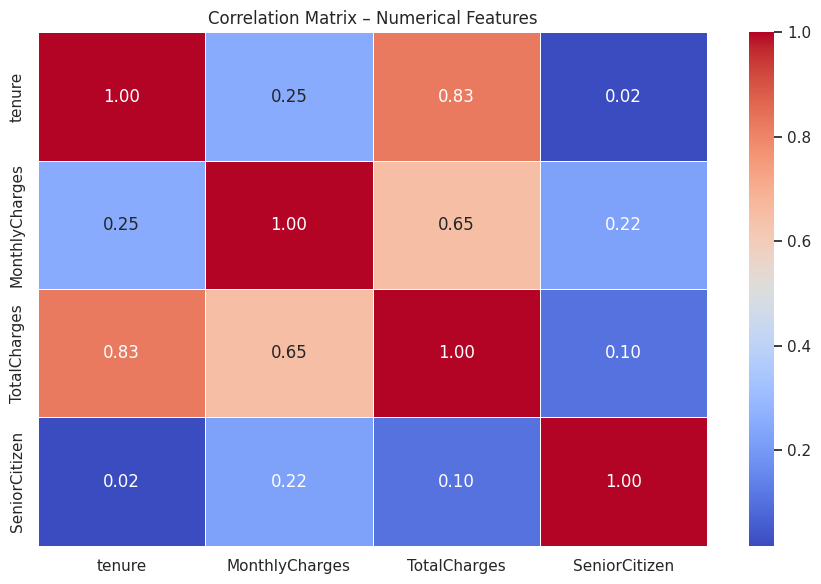

In [24]:
numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix – Numerical Features")
plt.tight_layout()
plt.show()

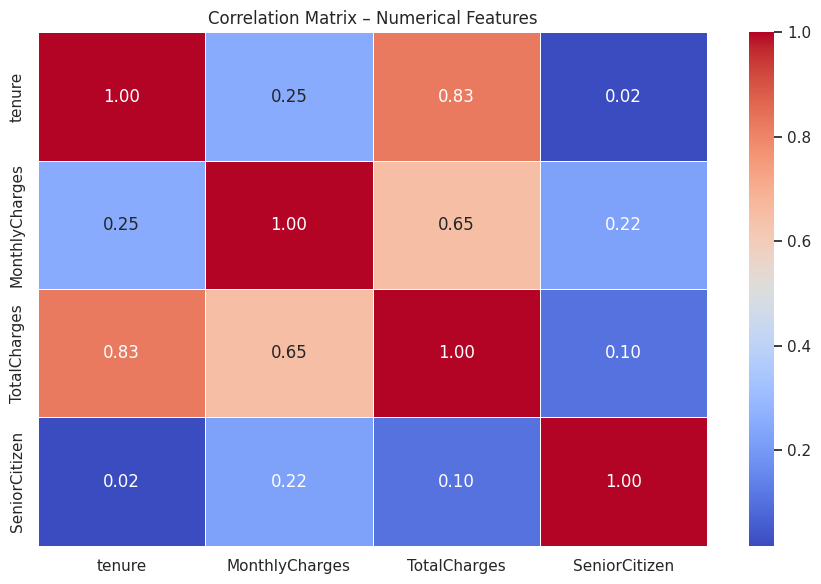

In [25]:
numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix – Numerical Features")
plt.tight_layout()
plt.show()

In [26]:
display(correlation_matrix.round(3))

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
tenure,1.000,0.248,0.826,0.017
MonthlyCharges,0.248,1.000,0.651,0.220
TotalCharges,0.826,0.651,1.000,0.103
SeniorCitizen,0.017,0.220,0.103,1.000


### EDA Finding 11 – Numerical Correlation Analysis

The correlation analysis reveals several relationships between numerical features.

**Key findings:**

1. **Tenure and TotalCharges (0.826):** A very strong positive correlation. Customers with longer tenure tend to accumulate higher total charges.

2. **MonthlyCharges and TotalCharges (0.651):** A strong positive correlation. Higher monthly charges tend to be associated with higher accumulated charges.

3. **Tenure and MonthlyCharges (0.248):** A weak positive correlation, suggesting that customer tenure has a limited linear relationship with monthly charges.

4. **SeniorCitizen:** This variable has weak correlations with the other numerical features.

**Machine Learning considerations:**

- Tenure and TotalCharges contain overlapping information.
- Multicollinearity should be considered when selecting and interpreting model features.
- TotalCharges may be useful, but its relationship with tenure should be evaluated during feature selection.

**Note:** Correlation measures linear association and does not imply causation.

In [27]:
churn_numeric_analysis = df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean().round(2)

display(churn_numeric_analysis)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


### EDA Finding 12 – Numerical Features by Churn Status

The comparison of numerical features between retained and churned customers reveals three important patterns.

**Tenure:**
- Retained customers have an average tenure of 37.57 months.
- Churned customers have an average tenure of 17.98 months.
- Churned customers have substantially shorter customer relationships.

**MonthlyCharges:**
- Retained customers pay an average of 61.27 per month.
- Churned customers pay an average of 74.44 per month.
- Higher monthly charges are associated with a higher churn rate.

**TotalCharges:**
- Retained customers have average total charges of 2549.91.
- Churned customers have average total charges of 1531.80.
- This difference is partly explained by the shorter tenure of churned customers.

**Key business insights:**
- Early customer retention should be a priority.
- Pricing and perceived service value should be investigated.
- New customers with high monthly charges may deserve additional attention.

**Note:** These are descriptive comparisons. They do not establish causality or statistical significance.